# Knowledge Extraction from Unstructured Text — Lauréats du prix Nobel de physique

**Objectif** : extraire des connaissances structurées (entités, relations, faits) à partir de textes bruts
et construire un *Knowledge Graph* (KG), puis comparer une chaîne de traitement « classique »
(règles + apprentissage automatique) à un LLM.

| Élément | Choix |
|---|---|
| Corpus principal | 150 introductions d'articles Wikipedia (EN) de lauréats du Nobel de physique (~21 500 mots) |
| Référence pour les relations | Faits Wikidata des mêmes personnes (lieu/date de naissance, universités, employeurs, prix) |
| Référence pour la NER | CoNLL-2003 (anglais, annoté PER / ORG / LOC / MISC) |
| Outils | NLTK, spaCy, scikit-learn, sklearn-crfsuite, Hugging Face Transformers, NetworkX, rdflib, pyvis |

Plan : **A** prétraitement et représentation → **B** NER (règles / spaCy / CRF) → **C** relations et KG →
**D** analyse, applications et comparaison avec un LLM.

> Tout tourne sur CPU. Le code réutilisable est dans `src/` ; ce notebook l'appelle et commente les résultats.

In [1]:
import sys, json, time, warnings
from pathlib import Path
from collections import Counter

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

from src.config import CORPUS_FILE, WIKIDATA_FILE, FIG_DIR, KG_DIR, PROCESSED_DIR, OUTPUT_DIR, RELATIONS
RESULTS = OUTPUT_DIR / "results"; RESULTS.mkdir(exist_ok=True)

# Données : téléchargées une seule fois (déjà fournies dans data/raw pour le corpus Wikipedia)
if not (CORPUS_FILE.exists() and (ROOT / "data/raw/conll2003/test.txt").exists()):
    from src import data_collection
    data_collection.main()

corpus = json.loads(CORPUS_FILE.read_text(encoding="utf-8"))
wikidata = json.loads(WIKIDATA_FILE.read_text(encoding="utf-8"))
print(len(corpus), "textes ;", corpus[0]["title"], "->", corpus[0]["url"])

150 textes ; Jack Steinberger -> https://en.wikipedia.org/wiki/Jack_Steinberger


## Partie A — Prétraitement et représentation du texte

### A.1 Nettoyage et normalisation
Les introductions Wikipedia contiennent du bruit : transcriptions phonétiques (`German: [ˈhans ˈbeːtə]`),
noms en écriture native, renvois `[1]`, tirets et guillemets typographiques.

On distingue **deux niveaux** :
* **nettoyage léger** (`clean_text`) : on garde casse et ponctuation, indispensables à la NER et au parsing ;
* **normalisation forte** (`normalize_doc`) : minuscules, lemmes, sans mots vides ni ponctuation → pour TF-IDF / clustering.

In [2]:
from src.preprocessing import clean_text, preprocess_corpus, nltk_pipeline, spacy_table, get_nlp

ex = next(d for d in corpus if d["title"].startswith("Hans Bethe") or "Bethe" in d["title"])
print("BRUT    :", ex["text"][:230], "\n")
print("NETTOYÉ :", clean_text(ex["text"])[:230])

BRUT    : Hans Albrecht Eduard Bethe (; German: [ˈhans ˈbeːtə] ; 2 July 1906 – 6 March 2005) was a German-American physicist who made major contributions to nuclear physics, astrophysics, quantum electrodynamics and solid-state physics, and 

NETTOYÉ : Hans Albrecht Eduard Bethe (2 July 1906 - 6 March 2005) was a German-American physicist who made major contributions to nuclear physics, astrophysics, quantum electrodynamics and solid-state physics, and received the Nobel Prize i


Prétraitement spaCy des 150 textes : 2.3 s
NORMALISÉ : jack steinberger bear hans jakob steinberger december german bear american physicist note work neutrinos subatomic particle consider elementary constituent matter recipient nobel prize physics leon lederman melvin schwartz discovery muon neutrino car


,count,mean,std,min,25%,50%,75%,max
tokens,150.0,164.5,137.9,42.0,76.0,109.0,191.0,769.0
phrases,150.0,6.1,5.2,1.0,3.0,4.0,7.0,27.0


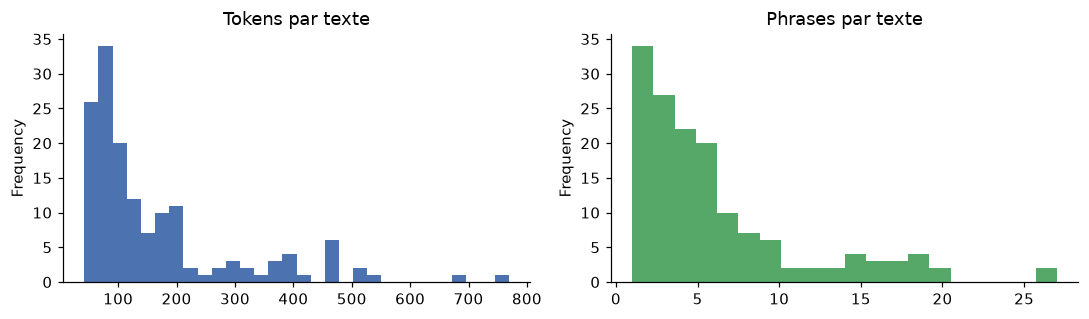

In [3]:
t0 = time.time()
corpus, docs = preprocess_corpus(corpus)          # spaCy : tokenisation, POS, lemmes, dépendances, NER
time_parse = time.time() - t0
print(f"Prétraitement spaCy des {len(docs)} textes : {time_parse:.1f} s")
print("NORMALISÉ :", corpus[0]["normalized"][:250])

stats = pd.DataFrame({"tokens": [d["n_tokens"] for d in corpus], "phrases": [d["n_sents"] for d in corpus]})
display(stats.describe().round(1).T)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
stats["tokens"].plot.hist(bins=30, ax=ax[0], color="#4C72B0", title="Tokens par texte")
stats["phrases"].plot.hist(bins=20, ax=ax[1], color="#55A868", title="Phrases par texte")
fig.tight_layout(); fig.savefig(FIG_DIR / "A_corpus_stats.png")

### A.2 Tokenisation, POS tagging, lemmatisation : NLTK vs spaCy

In [4]:
sentence = corpus[0]["clean"].split(". ")[0][:140]
nltk_df = pd.DataFrame(nltk_pipeline(sentence), columns=["token", "POS NLTK (PTB)", "lemme NLTK (WordNet)"])
spacy_df = pd.DataFrame(spacy_table(get_nlp()(sentence)))[["token", "pos", "tag", "lemma", "dep"]]
spacy_df.columns = ["token", "POS spaCy (UD)", "tag spaCy (PTB)", "lemme spaCy", "dépendance"]
display(pd.concat([nltk_df.head(18).reset_index(drop=True), spacy_df.head(18).reset_index(drop=True)], axis=1))

,token,POS NLTK (PTB),lemme NLTK (WordNet),token,POS spaCy (UD),tag spaCy (PTB),lemme spaCy,dépendance
0,Jack,NNP,jack,Jack,PROPN,NNP,Jack,compound
1,Steinberger,NNP,steinberger,Steinberger,PROPN,NNP,Steinberger,nsubj
2,(,(,(,(,PUNCT,-LRB-,(,punct
3,born,JJ,born,born,VERB,VBN,bear,amod
4,Hans,NNPS,han,Hans,PROPN,NNP,Hans,compound
5,Jakob,NNP,jakob,Jakob,PROPN,NNP,Jakob,compound
6,Steinberger,NNP,steinberger,Steinberger,PROPN,NNP,Steinberger,appos
7,;,:,;,;,PUNCT,:,;,punct
8,May,NNP,may,May,PROPN,NNP,May,appos
9,25,CD,25,25,NUM,CD,25,nummod


**Observation** : les deux tokeniseurs coupent pareil, mais la lemmatisation WordNet de NLTK abîme les noms propres
(`Hans` → `han`) et dépend d'un POS approximatif (`born` étiqueté adjectif). spaCy donne en plus l'arbre de
dépendances utilisé en Partie C : c'est lui qu'on garde pour la suite.

### A.3 Représentations numériques
* **TF-IDF** (unigrammes + bigrammes, sur le texte normalisé) : représentation creuse et interprétable.
* **Embeddings Transformer** : `all-MiniLM-L6-v2` (BERT distillé, 384 dimensions, mean pooling), sur le texte nettoyé.

In [5]:
from src.representation import tfidf_matrix, top_terms, bert_embeddings, choose_k, kmeans, cluster_top_terms, most_similar

titles = [d["title"] for d in corpus]
X_tfidf, vec = tfidf_matrix([d["normalized"] for d in corpus])
print("Matrice TF-IDF :", X_tfidf.shape, f"(densité {X_tfidf.nnz / np.prod(X_tfidf.shape):.3f})")
for i in range(3):
    print(f"  {titles[i]:<25}", top_terms(X_tfidf, vec, i, 6))

t0 = time.time()
E = bert_embeddings([d["clean"] for d in corpus])
print("Embeddings MiniLM :", E.shape, f"en {time.time() - t0:.1f} s sur CPU")

Matrice TF-IDF : (150, 2000) (densité 0.033)
  Jack Steinberger          ['steinberger', 'medal', 'recipient', 'physicist note', 'leon lederman', 'physics leon']
  Antony Hewish             ['radio astronomer', 'radio', 'astronomer', 'martin ryle', 'ryle', 'hewish']
  Hugh David Politzer       ['david', 'david gross', 'physics california', 'frank wilczek', 'tolman', 'hugh']


Embeddings MiniLM : (150, 384) en 7.9 s sur CPU


### A.4 Exploitation non supervisée : clustering et similarité
On compare les deux représentations avec K-Means (k choisi par le score silhouette, distance cosinus)
et une recherche des biographies les plus proches.

,2,3,4,5,6,7,8
TF-IDF,0.014,0.014,0.017,0.017,0.013,0.019,0.020
MiniLM,0.060,0.059,0.052,0.059,0.064,0.050,0.054


Cluster 0 (20 docs) : astrophysicist, astronomer, bear, university, discovery, physics, prize
Cluster 1 (30 docs) : physics, john, prize, physicist, american, nobel, nobel prize
Cluster 2 (5 docs) : nakamura, blue, akasaki, amano, hiroshi, isamu, semiconductor
Cluster 3 (33 docs) : laser, german, physics, quantum, prize, work, german physicist
Cluster 4 (31 docs) : nuclear, physics, study, atomic, laboratory, war, physicist
Cluster 5 (31 docs) : physics, theoretical, theoretical physicist, theory, physicist, prize, particle
Les plus proches d'Albert Einstein (MiniLM) : [('Philipp Lenard', 0.62), ('Eugene Wigner', 0.595), ('Werner Heisenberg', 0.581), ('Wilhelm Wien', 0.57), ('Max Planck', 0.565)]
Les plus proches d'Albert Einstein (TF-IDF) : [('Eugene Wigner', 0.238), ('Paul Dirac', 0.238), ('Werner Heisenberg', 0.23), ('Hans Bethe', 0.206), ('Enrico Fermi', 0.199)]


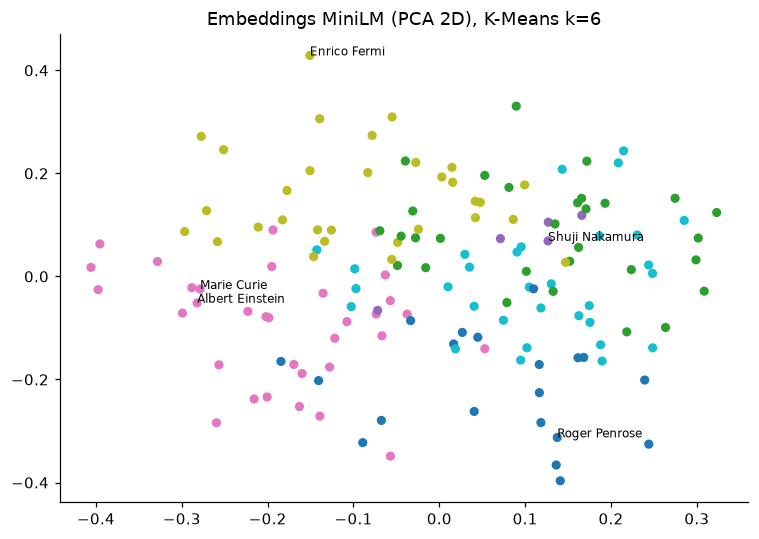

In [6]:
from sklearn.decomposition import PCA

k_tfidf, sil_tfidf = choose_k(X_tfidf.toarray())
k_bert, sil_bert = choose_k(E)
sil = pd.DataFrame({"TF-IDF": sil_tfidf, "MiniLM": sil_bert}).round(3)
sil.to_csv(RESULTS / "A_silhouette.csv")
display(sil.T)

labels = kmeans(E, k_bert)
terms = cluster_top_terms(X_tfidf, vec, labels, 7)
for c in sorted(terms):
    print(f"Cluster {c} ({(labels == c).sum()} docs) :", ", ".join(terms[c]))

P = PCA(n_components=2, random_state=0).fit_transform(E)
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(P[:, 0], P[:, 1], c=labels, cmap="tab10", s=25)
for name in ["Albert Einstein", "Marie Curie", "Enrico Fermi", "Shuji Nakamura", "Roger Penrose"]:
    if name in titles:
        i = titles.index(name); ax.annotate(name, P[i], fontsize=8)
ax.set_title(f"Embeddings MiniLM (PCA 2D), K-Means k={k_bert}")
fig.tight_layout(); fig.savefig(FIG_DIR / "A_clusters_pca.png")

print("Les plus proches d'Albert Einstein (MiniLM) :", most_similar(E, titles.index("Albert Einstein"), titles))
print("Les plus proches d'Albert Einstein (TF-IDF) :", most_similar(X_tfidf.toarray(), titles.index("Albert Einstein"), titles))

**Interprétation** : les scores silhouette sont faibles pour les deux représentations : toutes les
biographies se ressemblent (même genre de texte, même prix). Les embeddings MiniLM séparent quand même un peu
mieux les profils que TF-IDF (ex. physique théorique/quantique, lasers/optique, semi-conducteurs/lauréats japonais),
et leurs voisins sont thématiquement cohérents (Einstein est proche de Planck, Heisenberg, Wien).
TF-IDF reste utile pour *expliquer* un cluster par ses termes.

## Partie B — Reconnaissance et classification d'entités nommées

Le corpus Wikipedia n'a pas d'annotations : on évalue donc les modèles sur **CoNLL-2003**
(phrases de presse Reuters, 4 types : PER, ORG, LOC, MISC ; train = 14 041 phrases, test = 3 453).

| Approche | Principe |
|---|---|
| **Règles** (spaCy `EntityRuler`) | dictionnaire des entités vues dans le train + motifs (titre + Nom → PER, … + `University/Inc/Party` → ORG, adjectifs de nationalité → MISC) |
| **spaCy `en_core_web_sm`** | modèle statistique pré-entraîné (OntoNotes, 18 types), projeté vers les 4 types CoNLL |
| **CRF** | Conditional Random Field entraîné sur le train CoNLL (forme du mot, suffixes, POS, fenêtre ±2) |

Métrique : précision / rappel / F1 **au niveau entité** (`seqeval`) : une entité compte comme juste seulement
si ses frontières et son type sont exacts.

In [7]:
import spacy
from src.ner import load_conll, build_rule_ner, get_crf, run_all, evaluate, per_type_report, agreement, sent2features

train, test = load_conll("train"), load_conll("test")
print(f"CoNLL-2003 : {len(train)} phrases train, {len(test)} phrases test")
print("Exemple :", list(zip(test[5][0], test[5][2])))

rule_nlp, n_patterns = build_rule_ner(train)
spacy_nlp = spacy.load("en_core_web_sm")
t0 = time.time(); crf = get_crf(train); print(f"Règles : {n_patterns} motifs ; CRF prêt en {time.time() - t0:.1f} s")

preds, times = run_all(test, rule_nlp, spacy_nlp, crf)
gold = [s[2] for s in test]
ner_scores = pd.DataFrame([evaluate(k, gold, preds[k], times[k]) for k in preds]).set_index("model").round(3)
ner_scores.to_csv(RESULTS / "B_ner_scores.csv")
ner_scores

CoNLL-2003 : 14041 phrases train, 3453 phrases test
Exemple : [('China', 'B-LOC'), ('controlled', 'O'), ('most', 'O'), ('of', 'O'), ('the', 'O'), ('match', 'O'), ('and', 'O'), ('saw', 'O'), ('several', 'O'), ('chances', 'O'), ('missed', 'O'), ('until', 'O'), ('the', 'O'), ('78th', 'O'), ('minute', 'O'), ('when', 'O'), ('Uzbek', 'B-MISC'), ('striker', 'O'), ('Igor', 'B-PER'), ('Shkvyrin', 'I-PER'), ('took', 'O'), ('advantage', 'O'), ('of', 'O'), ('a', 'O'), ('misdirected', 'O'), ('defensive', 'O'), ('header', 'O'), ('to', 'O'), ('lob', 'O'), ('the', 'O'), ('ball', 'O'), ('over', 'O'), ('the', 'O'), ('advancing', 'O'), ('Chinese', 'B-MISC'), ('keeper', 'O'), ('and', 'O'), ('into', 'O'), ('an', 'O'), ('empty', 'O'), ('net', 'O'), ('.', 'O')]


Règles : 8028 motifs ; CRF prêt en 0.0 s


,precision,recall,f1,time_s
model,,,,
Règles (EntityRuler),0.751,0.518,0.613,4.9
spaCy en_core_web_sm,0.656,0.545,0.595,12.0
CRF (sklearn-crfsuite),0.821,0.808,0.814,0.5


,Règles (EntityRuler),spaCy en_core_web_sm,CRF (sklearn-crfsuite)
PER,0.257,0.646,0.865
ORG,0.650,0.360,0.739
LOC,0.763,0.749,0.854
MISC,0.705,0.614,0.773


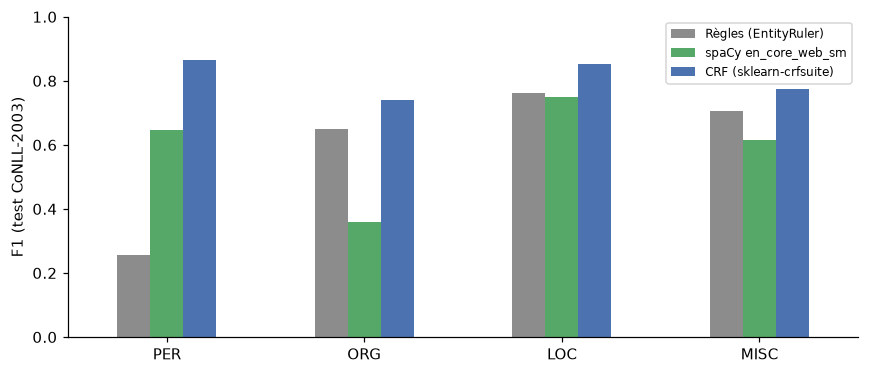

In [8]:
per_type = pd.DataFrame({m: {t: per_type_report(gold, p)[t]["f1-score"] for t in ["PER", "ORG", "LOC", "MISC"]}
                         for m, p in preds.items()}).round(3)
per_type.to_csv(RESULTS / "B_ner_f1_per_type.csv")
display(per_type)
ax = per_type.plot.bar(figsize=(8, 3.5), rot=0, color=["#8C8C8C", "#55A868", "#4C72B0"])
ax.set_ylabel("F1 (test CoNLL-2003)"); ax.set_ylim(0, 1); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "B_ner_f1_per_type.png")

**Analyse des erreurs** : quelques phrases où les approches ne sont pas d'accord.

In [9]:
from src.ner import spans_from_tags
def ents(tokens, tags):
    return [(" ".join(tokens[s:e]), t) for s, e, t in spans_from_tags(list(tags))]

shown = 0
for i, (toks, _, g) in enumerate(test):
    if 8 <= len(toks) <= 25 and len({tuple(preds[m][i]) for m in preds} | {tuple(g)}) == 4:
        print("PHRASE :", " ".join(toks))
        print("  référence :", ents(toks, g))
        for m in preds:
            print(f"  {m:<22}:", ents(toks, preds[m][i]))
        print(); shown += 1
    if shown == 3:
        break

PHRASE : SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRISE DEFEAT .
  référence : [('JAPAN', 'LOC'), ('CHINA', 'PER')]
  Règles (EntityRuler)  : []
  spaCy en_core_web_sm  : [('DEFEAT', 'ORG')]
  CRF (sklearn-crfsuite): [('JAPAN', 'PER'), ('LUCKY', 'ORG'), ('CHINA', 'LOC')]

PHRASE : RUGBY UNION - CUTTITTA BACK FOR ITALY AFTER A YEAR .
  référence : [('RUGBY UNION', 'ORG'), ('CUTTITTA', 'PER'), ('ITALY', 'LOC')]
  Règles (EntityRuler)  : [('RUGBY UNION', 'ORG')]
  spaCy en_core_web_sm  : []
  CRF (sklearn-crfsuite): [('RUGBY UNION', 'ORG'), ('CUTTITTA', 'PER')]

PHRASE : SOCCER - LATE GOALS GIVE JAPAN WIN OVER SYRIA .
  référence : [('JAPAN', 'LOC'), ('SYRIA', 'LOC')]
  Règles (EntityRuler)  : []
  spaCy en_core_web_sm  : [('SYRIA', 'LOC')]
  CRF (sklearn-crfsuite): [('JAPAN', 'MISC'), ('SYRIA', 'LOC')]



In [10]:
# Ce que le CRF a appris : traits les plus fortement associés à chaque type
state = pd.DataFrame([(lab, feat, w) for (feat, lab), w in crf.state_features_.items()],
                     columns=["label", "trait", "poids"])
top = state[state.label.str.startswith("B-")].sort_values("poids", ascending=False).groupby("label").head(4)
top.sort_values(["label", "poids"], ascending=[True, False])

,label,trait,poids
15510,B-LOC,2:w.lower:yellow,4.960621
23950,B-LOC,1:w.lower:1996-08-26,4.952603
9783,B-LOC,w.lower:england,4.723901
25017,B-LOC,1:w.lower:1996-08-27,4.604985
4937,B-MISC,w[-3:]:ese,4.550436
221,B-MISC,w.lower:german,4.512465
8770,B-MISC,w[:3]:Isl,3.622816
10443,B-MISC,w.lower:dutch,3.557257
12204,B-ORG,-1:w.lower:v,5.569685
20364,B-ORG,1:w.lower:arose,4.949972


### B.2 Classification des entités du corpus Wikipedia
On applique maintenant le modèle spaCy (18 catégories : PERSON, ORG, GPE, DATE, NORP, WORK_OF_ART…) au corpus.
Le CRF, entraîné sur la presse, ne connaît que 4 types ; on mesure son accord avec spaCy (domaine différent).

2919 mentions d'entités, 1599 distinctes


,entités les plus fréquentes
catégorie,
PERSON,"Lawrence (10), Einstein (9), Curie (8), Segrè (8)"
ORG,"the Manhattan Project (12), Physics (12), the University of Cambridge (9), Rayleigh (9)"
GPE,"the United States (14), Fermi (14), Cambridge (9), Germany (8)"
DATE,"1946 (10), 1999 (9), 1972 (8), 1988 (7)"
NORP,"American (60), German (32), British (22), French (12)"
WORK_OF_ART,"Nobel Prize in Physics (76), the Nobel Prize in Physics (55), Nobel (9), Nobel Prize (8)"
LAW,"the Matteucci Medal (1), The First Three Minutes (1)"
PRODUCT,"Waals (3), Von Klitzing (1), École (1), Calcutta (1)"


,CRF vs spaCy sur Wikipedia (PER/ORG/LOC)
entités spaCy,1572.000
entités CRF,1947.000
communes,806.000
accord_precision,0.414
accord_recall,0.513
accord_f1,0.458


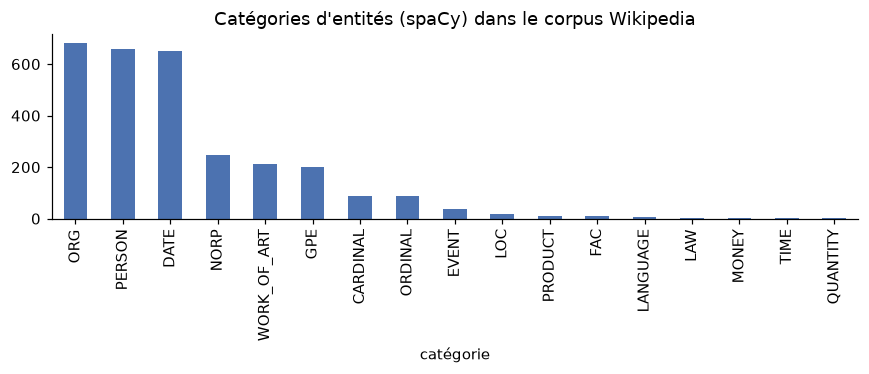

In [11]:
ent_rows = [(e.text, e.label_) for doc in docs for e in doc.ents]
ent_df = pd.DataFrame(ent_rows, columns=["entité", "catégorie"])
cat_counts = ent_df["catégorie"].value_counts()
print(f"{len(ent_df)} mentions d'entités, {ent_df['entité'].nunique()} distinctes")
fig, ax = plt.subplots(figsize=(8, 3.5))
cat_counts.plot.bar(ax=ax, color="#4C72B0"); ax.set_title("Catégories d'entités (spaCy) dans le corpus Wikipedia")
plt.tight_layout(); plt.savefig(FIG_DIR / "B_entity_categories.png")

top_ents = (ent_df.groupby("catégorie")["entité"].agg(lambda s: ", ".join(f"{e} ({n})" for e, n in Counter(s).most_common(4))))
display(top_ents.loc[[c for c in ["PERSON", "ORG", "GPE", "DATE", "NORP", "WORK_OF_ART", "LAW", "PRODUCT"] if c in top_ents.index]].to_frame("entités les plus fréquentes"))

agr = agreement(docs, crf)
pd.Series(agr).to_csv(RESULTS / "B_crf_spacy_agreement.csv")
cat_counts.to_csv(RESULTS / "B_entity_categories.csv")
pd.Series(agr).round(3).to_frame("CRF vs spaCy sur Wikipedia (PER/ORG/LOC)")

**Constats Partie B**
* Le **CRF** est nettement le meilleur sur CoNLL : il est entraîné sur ce domaine et ce schéma d'annotation.
* Les **règles** ont une bonne précision mais un rappel faible : une entité absente du dictionnaire
  est presque toujours ratée (pas de généralisation).
* **spaCy small** est pénalisé ici par le décalage de schéma (OntoNotes ≠ CoNLL, surtout MISC) et de domaine
  (titres sportifs en majuscules) ; il reste le plus utile sur Wikipedia car il reconnaît DATE, WORK_OF_ART, etc.
* L'accord CRF/spaCy sur Wikipedia est moyen : le CRF entraîné sur Reuters se transfère mal à un autre domaine.

Erreurs typiques sur Wikipedia : `Antony Hewish` étiqueté ORG, `Nobel Prize in Physics` étiqueté WORK_OF_ART,
`the Matteucci Medal` étiqueté LAW, `CERN` étiqueté GPE. La Partie C compense en partie ces erreurs avec des règles
sur le texte (« Prize », « Medal », « University »…).

## Partie C — Extraction de relations et construction du Knowledge Graph

### C.1 Extraction par analyse en dépendances
Schéma de relations (choisi pour être vérifiable avec Wikidata) :
`born_in`, `born_on`, `died_in`, `educated_at`, `worked_at`, `award_received` (+ `shared_prize_with`, non évaluée).

Méthode (`src/relation_extraction.py`) : pour chaque entité de la phrase, on remonte ses ancêtres dans l'arbre de
dépendances jusqu'au premier **mot déclencheur** (`bear` → naissance, `educate/study/graduate` → études,
`professor/work/join` → emploi, `win/receive/award` → prix). Le sujet est le `nsubj` du verbe ; les pronoms
*he/she/who* sont rattachés à la personne de l'article (coréférence heuristique). Le type d'entité doit être
compatible avec la relation (lieu pour `born_in`, organisation pour `worked_at`…).

In [12]:
from spacy import displacy
from src.relation_extraction import DependencyRelationExtractor, ALL_RELATIONS

demo = get_nlp()("Born in Belgium, he was educated at the Catholic University of Leuven and worked at CERN.")
svg = displacy.render(demo, style="dep", jupyter=False, options={"compact": True, "distance": 95})
(FIG_DIR / "C_dependency_example.svg").write_text(svg, encoding="utf-8")
displacy.render(demo, style="dep", jupyter=True, options={"compact": True, "distance": 95})
for e in demo.ents:
    print(f"{e.text:<35} {e.label_:<5} ancêtres : {[a.lemma_ for a in e.root.ancestors]}")

Belgium                             GPE   ancêtres : ['in', 'bear', 'educate']
the Catholic University of Leuven   ORG   ancêtres : ['at', 'educate']
CERN                                GPE   ancêtres : ['at', 'work', 'educate']


In [13]:
extractor = DependencyRelationExtractor(get_nlp())
t0 = time.time()
triples = extractor.extract_corpus(corpus, docs)
time_classic = time.time() - t0
print(f"{len(triples)} triplets extraits en {time_classic:.1f} s")
tri_df = pd.DataFrame(triples)
display(tri_df["relation"].value_counts().to_frame("nombre"))
tri_df[["subject", "relation", "object", "trigger", "sentence"]].sample(8, random_state=1)

699 triplets extraits en 0.3 s


,nombre
relation,
worked_at,220
award_received,178
born_on,146
shared_prize_with,123
educated_at,19
born_in,11
died_in,2


,subject,relation,object,trigger,sentence
584,Frank Wilczek,shared_prize_with,H. David Politzer,shared,"He shared the 2004 Nobel Prize in Physics with David Gross and H. David Politzer ""for the discovery of asymptotic fr..."
417,Luis Walter Alvarez,worked_at,Radiation Laboratory,work,"After receiving his PhD from the University of Chicago in 1936, Alvarez went to work for Ernest Lawrence at the Radi..."
606,David Gross,award_received,Nobel Prize in Physics,shared,"He shared the 2004 Nobel Prize in Physics with Frank Wilczek and Hugh David Politzer ""for the discovery of asymptoti..."
349,Duncan Haldane,worked_at,Sherman Fairchild University,Professor,Frederick Duncan Michael Haldane (born 14 September 1951) is a British physicist who is currently the Sherman Fairch...
134,Melvin Schwartz,born_on,"November 2, 1932",,"Melvin Schwartz (SHWORTS; November 2, 1932 - August 28, 2006) was an American physicist."
502,Leon M. Lederman,worked_at,Illinois Mathematics and Science Academy,founded,"He founded the Illinois Mathematics and Science Academy, in Aurora, Illinois in 1986, where he was resident scholar ..."
117,Nevill Mott,award_received,Nobel Prize in Physics,won,Sir Nevill Francis Mott (30 September 1905 - 8 August 1996) was a British theoretical physicist who won the Nobel Pr...
528,Gustav Ludwig Hertz,award_received,Nobel Prize in Physics,shared,Gustav Ludwig Hertz (22 July 1887 - 30 October 1975) was a German experimental physicist who shared the 1925 Nobel P...


### C.2 Évaluation automatique avec Wikidata
* **Précision** : part des triplets dont l'objet correspond à un fait Wikidata de la personne (libellé ou alias).
  C'est une *borne inférieure* : un fait vrai mais absent de Wikidata est compté faux.
* **Rappel** : parmi les faits Wikidata dont l'objet est **écrit dans le texte**, part retrouvée.

In [14]:
from src.evaluation import evaluate_triples, groundedness, obj_match
from src.relation_extraction import display_name

eval_classic = evaluate_triples(triples, corpus, wikidata)
eval_classic.to_csv(RESULTS / "C_relations_eval_classic.csv", index=False)
display(eval_classic)

# Faux positifs selon Wikidata : beaucoup sont en réalité corrects (Wikidata incomplet)
names = {d["id"]: display_name(d["title"]) for d in corpus}
fp = [t for t in triples if t["relation"] in ("worked_at", "educated_at") and t["subject"] == names[t["doc_id"]]
      and not any(obj_match(t["object"], f) for f in wikidata[t["doc_id"]][t["relation"]])]
pd.DataFrame(fp)[["subject", "relation", "object", "trigger"]].sample(10, random_state=0)

,relation,extraits,corrects (Wikidata),faits Wikidata dans le texte,retrouvés,précision,rappel,F1
0,born_in,11,6,8,4,0.545,0.500,0.522
1,born_on,145,145,150,145,1.000,0.967,0.983
2,died_in,2,1,22,1,0.500,0.045,0.083
3,educated_at,18,11,61,12,0.611,0.197,0.298
4,worked_at,219,101,132,93,0.461,0.705,0.557
5,award_received,175,165,174,162,0.943,0.931,0.937
6,TOTAL,570,429,547,417,0.753,0.762,0.757


,subject,relation,object,trigger
8,Albert Fert,worked_at,Thales Group,director
50,Zhores Alferov,worked_at,State Duma,serving
43,Carl Wieman,educated_at,STEM,education
24,Edward Victor Appleton,worked_at,Western Front,served
63,Frederick Reines,worked_at,Operation Greenhouse,director
98,Barry Barish,worked_at,Nobel Laureate,physicist
54,Emilio Segrè,worked_at,Physics Laboratory,director
90,Eugene Wigner,worked_at,General Advisory Committee,served
7,Albert Fert,worked_at,National Scientific Research Centre,director
111,David Gross,worked_at,KITP,director


### C.3 Construction du Knowledge Graph (NetworkX) et exports
Nœuds typés (`Person`, `Organization`, `Place`, `Award`, `Year`), arcs étiquetés par la relation, avec la phrase
source en attribut (provenance). Exports : **CSV**, **RDF/Turtle** (rdflib), **GraphML** (importable dans Gephi
ou Neo4j), **HTML interactif** (pyvis).

In [15]:
from src.kg import build_kg, kg_stats, top_nodes, export_all, draw_subgraph, ego_nodes, overview_nodes, to_pyvis

G = build_kg(triples)
stats_cls = kg_stats(G)
(RESULTS / "C_kg_stats.json").write_text(json.dumps(stats_cls, ensure_ascii=False, indent=1), encoding="utf-8")
display(pd.Series(stats_cls).to_frame("KG classique"))
n_rdf = export_all(G, triples, KG_DIR, "kg_classic")
to_pyvis(G, KG_DIR / "kg_classic_interactive.html")
print(f"Exports : {n_rdf} triplets RDF -> outputs/kg/kg_classic.ttl, .graphml, _triples.csv, _interactive.html")

print("\nOrganisations les plus connectées :", top_nodes(G, "Organization", 8))
print("Prix les plus fréquents          :", top_nodes(G, "Award", 6))

,KG classique
nœuds,492
arcs,699
types de nœuds,"{'Person': 197, 'Year': 77, 'Award': 32, 'Organization': 173, 'Place': 13}"
relations,"{'born_on': 146, 'award_received': 178, 'worked_at': 220, 'shared_prize_with': 123, 'born_in': 11, 'educated_at': 19..."
composantes connexes,4
taille plus grande composante,484
densité,0.00561


Exports : 1682 triplets RDF -> outputs/kg/kg_classic.ttl, .graphml, _triples.csv, _interactive.html

Organisations les plus connectées : [('Manhattan Project', 8), ('University of Cambridge', 7), ('University of California', 6), ('University of Chicago', 5), ('Massachusetts Institute of Technology', 5), ('Stanford University', 5), ('University of California, Berkeley', 5), ('Princeton University', 5)]
Prix les plus fréquents          : [('Nobel Prize in Physics', 142), ('Wolf Prize', 3), ('Ernest Orlando Lawrence Award', 2), ('National Medal of Science', 2), ('United States National Medal of Science', 1), ('Matteucci Medal', 1)]


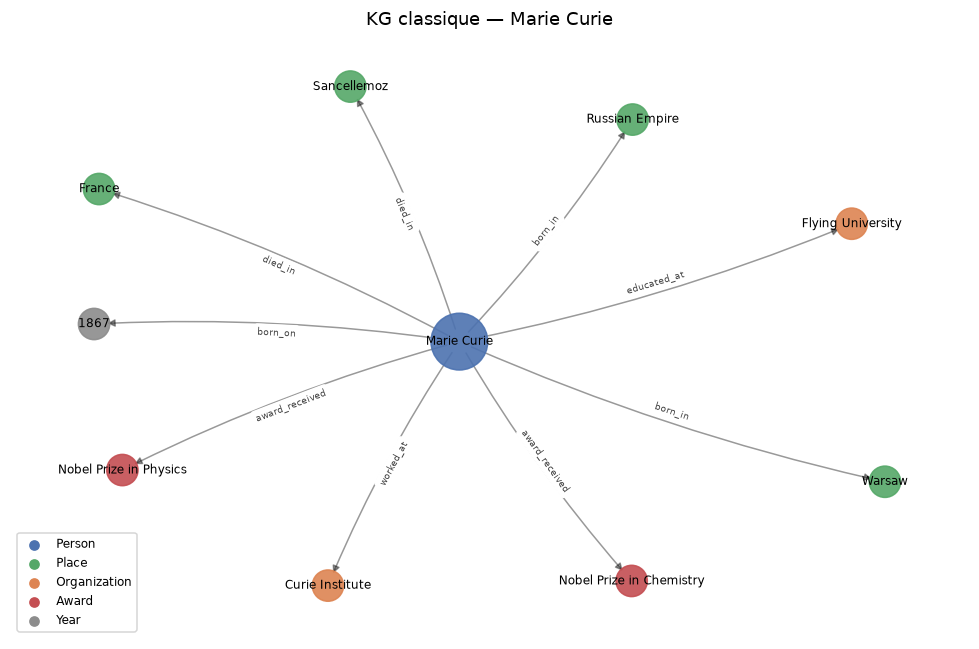

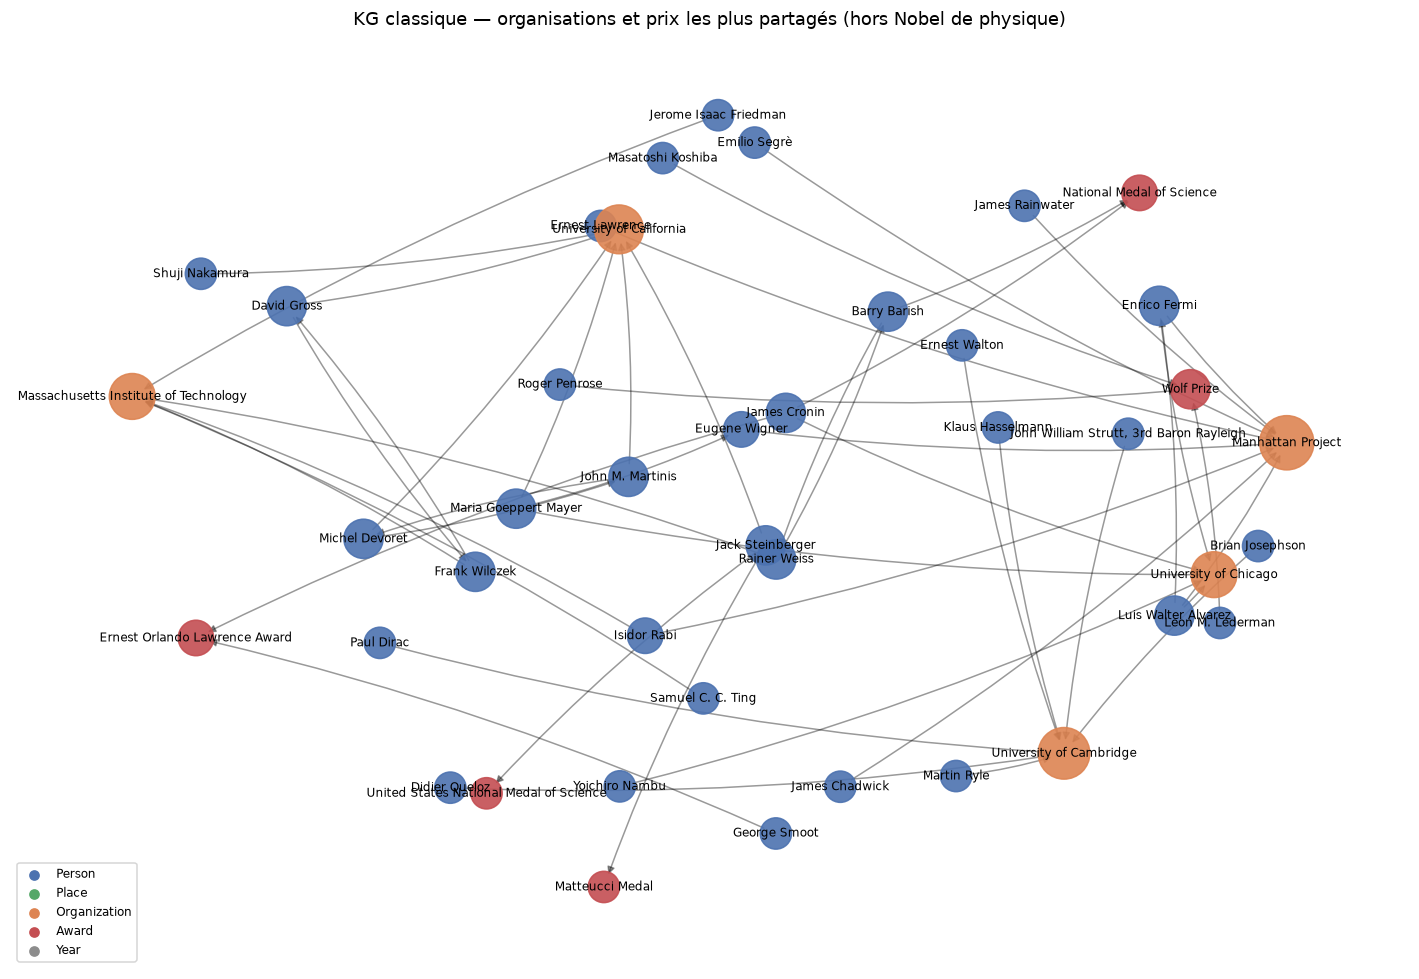

In [16]:
draw_subgraph(G, ego_nodes(G, "Marie Curie"), FIG_DIR / "C_kg_ego_marie_curie.png", "KG classique — Marie Curie", figsize=(9, 6))
plt.show()
draw_subgraph(G, overview_nodes(G, 10), FIG_DIR / "C_kg_overview.png",
              "KG classique — organisations et prix les plus partagés (hors Nobel de physique)", edge_labels=False)
plt.show()

## Partie D — Analyse, applications et comparaison avec un LLM

### D.1 Extraction par LLM
Modèle : **Qwen2.5-1.5B-Instruct**, exécuté **localement sur CPU** avec Hugging Face Transformers (gratuit,
sans clé API). Prompt *few-shot* (1 exemple) qui impose une sortie JSON avec le même schéma de relations.
Le même module accepte une API compatible OpenAI (Groq gratuit, Ollama) pour un modèle plus gros.

Le LLM est lent sur CPU : les réponses ont été générées une fois par
`python -m src.llm_extraction` puis mises en **cache** (`data/processed/llm_cache_*.json`). Ce notebook relit le cache.

In [17]:
from src.llm_extraction import (cache_path, load_cache, kg_triples_from_cache, ner_tags_from_output,
                                DEFAULT_HF_MODEL, KG_SYSTEM)
LLM_MODEL = DEFAULT_HF_MODEL
kg_cache = load_cache(cache_path("kg", LLM_MODEL))
ner_cache = load_cache(cache_path("ner", LLM_MODEL))
print(f"Cache LLM : {len(kg_cache)} biographies, {len(ner_cache)} phrases CoNLL")
assert kg_cache and ner_cache, "Lancer d'abord : python -m src.llm_extraction"
first = next(iter(kg_cache))
print("\nExemple de réponse brute pour", names[first], ":\n", kg_cache[first]["raw"][:600])

Cache LLM : 150 biographies, 100 phrases CoNLL

Exemple de réponse brute pour Jack Steinberger :
 {"born_in": ["Germany"], "born_on": ["May 25, 1921"], "died_in": ["United States"], "educated_at": ["University of California, Berkeley"], "worked_at": ["Columbia University", "CERN"], "award_received": ["Nobel Prize in Physics", "National Medal of Science", "Matteucci Medal"], "shared_prize_with": ["Leon M. Lederman", "Melvin Schwartz"]}


### D.2 NER : LLM vs CRF vs spaCy vs règles (mêmes phrases)

In [18]:
from seqeval.metrics import precision_score, recall_score, f1_score
keys = sorted(ner_cache, key=int)
toks_s = [ner_cache[k]["tokens"] for k in keys]
gold_s = [ner_cache[k]["gold"] for k in keys]
llm_out = [ner_tags_from_output(t, ner_cache[k]["raw"]) for t, k in zip(toks_s, keys)]
llm_tags = [t for t, _ in llm_out]

# les autres approches sur exactement les mêmes phrases
index = {tuple(s[0]): i for i, s in enumerate(test)}
ids = [index[tuple(t)] for t in toks_s]
rows = []
for m in preds:
    p = [preds[m][i] for i in ids]
    rows.append({"modèle": m, "précision": precision_score(gold_s, p), "rappel": recall_score(gold_s, p), "F1": f1_score(gold_s, p)})
rows.append({"modèle": f"LLM {LLM_MODEL.split('/')[-1]}", "précision": precision_score(gold_s, llm_tags),
             "rappel": recall_score(gold_s, llm_tags), "F1": f1_score(gold_s, llm_tags)})
ner_llm_cmp = pd.DataFrame(rows).set_index("modèle").round(3)
ner_llm_cmp["JSON valide"] = ""
ner_llm_cmp.loc[ner_llm_cmp.index[-1], "JSON valide"] = f"{np.mean([ok for _, ok in llm_out]):.0%}"
ner_llm_cmp["temps / phrase (s)"] = [round(times[m] / len(test), 4) for m in preds] + [round(np.mean([ner_cache[k]["seconds"] for k in keys]), 2)]
ner_llm_cmp.to_csv(RESULTS / "D_ner_llm_comparison.csv")
print(f"{len(keys)} phrases du test CoNLL (échantillon aléatoire fixe)")
ner_llm_cmp

100 phrases du test CoNLL (échantillon aléatoire fixe)


,précision,rappel,F1,JSON valide,temps / phrase (s)
modèle,,,,,
Règles (EntityRuler),0.814,0.520,0.635,,0.0014
spaCy en_core_web_sm,0.700,0.623,0.659,,0.0035
CRF (sklearn-crfsuite),0.837,0.820,0.828,,0.0002
LLM Qwen2.5-1.5B-Instruct,0.356,0.193,0.250,100%,8.7800


### D.3 Knowledge Graph : LLM vs approche classique (mêmes biographies)
Critères : qualité (précision / rappel / F1 vs Wikidata), **ancrage** dans le texte (objet présent dans la source :
mesure simple des hallucinations), conformité au format (JSON valide, clés hors schéma), taille du KG, coût en temps.

In [19]:
llm_triples, llm_stats = kg_triples_from_cache(kg_cache, corpus)
llm_ids = [d["id"] for d in corpus if d["id"] in kg_cache]
classic_sub = [t for t in triples if t["doc_id"] in set(llm_ids)]

eval_llm = evaluate_triples(llm_triples, corpus, wikidata, doc_ids=llm_ids)
eval_classic_sub = evaluate_triples(classic_sub, corpus, wikidata, doc_ids=llm_ids)
cmp_rel = pd.DataFrame({"P classique": eval_classic_sub.set_index("relation")["précision"],
                        "R classique": eval_classic_sub.set_index("relation")["rappel"],
                        "F1 classique": eval_classic_sub.set_index("relation")["F1"],
                        "P LLM": eval_llm.set_index("relation")["précision"],
                        "R LLM": eval_llm.set_index("relation")["rappel"],
                        "F1 LLM": eval_llm.set_index("relation")["F1"]})
cmp_rel.to_csv(RESULTS / "D_relations_by_type.csv")
print(f"Comparaison sur {len(llm_ids)} biographies")
cmp_rel

Comparaison sur 150 biographies


,P classique,R classique,F1 classique,P LLM,R LLM,F1 LLM
relation,,,,,,
born_in,0.545,0.500,0.522,0.160,0.125,0.140
born_on,1.000,0.967,0.983,1.000,0.493,0.660
died_in,0.500,0.045,0.083,0.130,0.136,0.133
educated_at,0.611,0.197,0.298,0.384,0.721,0.501
worked_at,0.461,0.705,0.557,0.347,0.523,0.417
award_received,0.943,0.931,0.937,0.770,0.902,0.831
TOTAL,0.753,0.762,0.757,0.544,0.636,0.586


In [20]:
G_llm = build_kg(llm_triples)
G_cls = build_kg(classic_sub)
export_all(G_llm, llm_triples, KG_DIR, "kg_llm")
to_pyvis(G_llm, KG_DIR / "kg_llm_interactive.html")

def key(t):
    from src.evaluation import norm
    from src.relation_extraction import year_of
    o = year_of(t["object"]) if t["relation"] == "born_on" else norm(t["object"])
    return (t["doc_id"], t["relation"], o)
k_cls, k_llm = {key(t) for t in classic_sub}, {key(t) for t in llm_triples}

tot_c = eval_classic_sub.set_index("relation").loc["TOTAL"]
tot_l = eval_llm.set_index("relation").loc["TOTAL"]
comparison = pd.DataFrame({
    "Approche classique (spaCy + dépendances)": {
        "triplets": len(classic_sub), "entités (nœuds)": G_cls.number_of_nodes(),
        "précision vs Wikidata": tot_c["précision"], "rappel (faits dans le texte)": tot_c["rappel"], "F1": tot_c["F1"],
        "ancrage dans le texte": round(groundedness(classic_sub, corpus), 3),
        "sortie conforme au schéma": "100 % (par construction)",
        "temps total (s)": round((time_parse + time_classic) * len(llm_ids) / len(corpus), 1),   # parsing spaCy + règles
        "matériel / coût": "CPU, ~15 Mo de modèle", "explicabilité": "phrase + mot déclencheur"},
    f"LLM ({LLM_MODEL.split('/')[-1]}, CPU)": {
        "triplets": len(llm_triples), "entités (nœuds)": G_llm.number_of_nodes(),
        "précision vs Wikidata": tot_l["précision"], "rappel (faits dans le texte)": tot_l["rappel"], "F1": tot_l["F1"],
        "ancrage dans le texte": round(groundedness(llm_triples, corpus), 3),
        "sortie conforme au schéma": f"JSON valide {llm_stats['json_valide']}/{llm_stats['docs']}, clés hors schéma : {llm_stats['clés_hors_schéma']}, valeurs « Not mentioned » : {llm_stats['valeurs_vides_écrites']}",
        "temps total (s)": round(llm_stats["temps_total_s"], 1),
        "matériel / coût": "CPU, ~3 Go de modèle", "explicabilité": "aucune (boîte noire)"}})
comparison.loc["triplets communs (même doc, relation, objet)"] = [len(k_cls & k_llm)] * 2
comparison.loc["Jaccard entre les deux KG"] = [round(len(k_cls & k_llm) / len(k_cls | k_llm), 3)] * 2
comparison.to_csv(RESULTS / "D_kg_comparison.csv")
comparison

,Approche classique (spaCy + dépendances),"LLM (Qwen2.5-1.5B-Instruct, CPU)"
triplets,699,829
entités (nœuds),492,585
précision vs Wikidata,0.753,0.544
rappel (faits dans le texte),0.762,0.636
F1,0.757,0.586
ancrage dans le texte,1.0,0.89
sortie conforme au schéma,100 % (par construction),"JSON valide 146/150, clés hors schéma : 0, valeurs « Not mentioned » : 9"
temps total (s),2.5,4315.7
matériel / coût,"CPU, ~15 Mo de modèle","CPU, ~3 Go de modèle"
explicabilité,phrase + mot déclencheur,aucune (boîte noire)


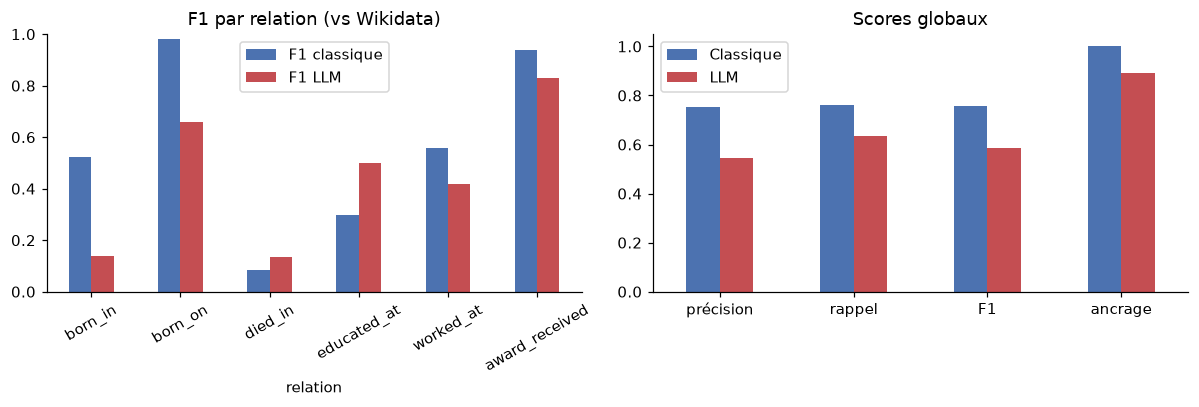

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
cmp_rel.loc[RELATIONS, ["F1 classique", "F1 LLM"]].plot.bar(ax=ax[0], rot=30, color=["#4C72B0", "#C44E52"])
ax[0].set_title("F1 par relation (vs Wikidata)"); ax[0].set_ylim(0, 1)
crit = pd.DataFrame({"Classique": [tot_c["précision"], tot_c["rappel"], tot_c["F1"], groundedness(classic_sub, corpus)],
                     "LLM": [tot_l["précision"], tot_l["rappel"], tot_l["F1"], groundedness(llm_triples, corpus)]},
                    index=["précision", "rappel", "F1", "ancrage"])
crit.plot.bar(ax=ax[1], rot=0, color=["#4C72B0", "#C44E52"]); ax[1].set_ylim(0, 1.05); ax[1].set_title("Scores globaux")
fig.tight_layout(); fig.savefig(FIG_DIR / "D_classic_vs_llm.png")

**Lecture des résultats** :
* Le LLM a un **meilleur rappel sur `educated_at`** : il comprend des formulations variées (« he studied physics
  under X at Y », « after his doctorate at Y ») que nos règles ne couvrent pas.
* Il est **moins précis** sur presque toutes les relations : confusion lieu de naissance / nationalité
  (« German-born » → *Germany*), employeurs inventés ou déduits, et il renvoie moins souvent la date de naissance.
* Sur la NER CoNLL, le petit LLM est très en dessous du CRF : phrases courtes de dépêches, tableaux sportifs,
  et consigne d'étiquetage (MISC, ORG sportif) qu'il ne connaît pas sans exemples annotés.
* Son KG est plus gros (plus de triplets, plus de nœuds) mais ~10 % des objets n'apparaissent pas dans le texte.

91 triplets LLM dont l'objet n'apparaît pas tel quel dans le texte, par exemple :


,subject,relation,object
0,Jack Steinberger,born_in,Germany
1,Francis Halzen,award_received,IceCube Neutrino Observatory Principal Investigator
2,Niels Bohr,worked_at,Risø Laboratory
3,Niels Bohr,award_received,Dirac Medal
4,Yang Chen-Ning,educated_at,Princeton University
5,Yang Chen-Ning,worked_at,Yale University
6,Ilya Frank,award_received,Soviet state prize
7,Ferenc Krausz,born_in,Hungary
8,Peter Grünberg,educated_at,Universität Heidelberg
9,Peter Grünberg,worked_at,Max Planck Institute for Solid State Research


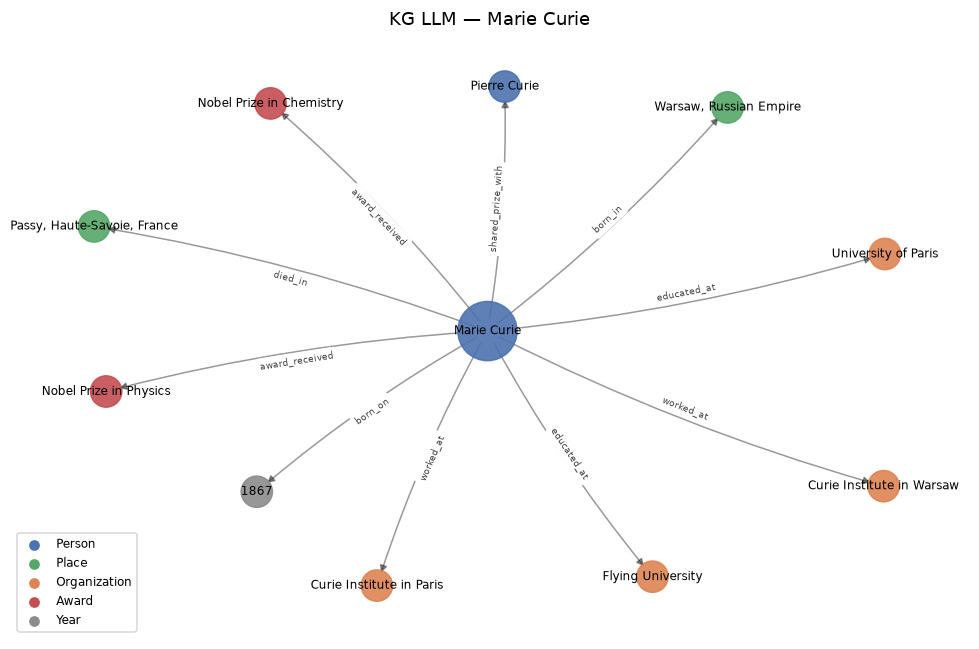

In [22]:
# Exemples d'erreurs du LLM : objets absents du texte (hallucinations) ou mauvaise relation
from src.evaluation import norm
texts = {d["id"]: norm(d["clean"]) for d in corpus}
halluc = [t for t in llm_triples if t["relation"] != "born_on" and norm(t["object"]) not in texts[t["doc_id"]]]
print(f"{len(halluc)} triplets LLM dont l'objet n'apparaît pas tel quel dans le texte, par exemple :")
display(pd.DataFrame(halluc)[["subject", "relation", "object"]].head(10))

person = next(p for p in ["Marie Curie", "Enrico Fermi", "Niels Bohr"] if p in G_llm)
fig = draw_subgraph(G_llm, ego_nodes(G_llm, person), FIG_DIR / "D_kg_llm_ego.png", f"KG LLM — {person}", figsize=(9, 6))
plt.show()

### D.4 Applications : question-réponse et recommandation sur le KG
Le KG permet de répondre à des questions factuelles **avec la source** (phrase d'origine), ce qu'un moteur de
recherche plein texte ou un LLM seul ne garantit pas.

In [23]:
from src.kg import answer, similar_people
questions = ["Where was Marie Curie born?", "Who worked at CERN?", "Who worked at Bell Labs?",
             "Which awards did Enrico Fermi receive?", "Who studied at the University of Cambridge?",
             "Who shared the prize with John Bardeen?", "Who received the Wolf Prize?"]
qa = pd.DataFrame({"question": questions,
                   "KG classique": [answer(G, q) for q in questions],
                   "KG LLM": [answer(G_llm, q) for q in questions]})
qa.to_csv(RESULTS / "D_qa.csv", index=False)
display(qa)

print("Recommandation (Jaccard sur organisations et prix) — profils proches d'Enrico Fermi :")
for name, score, shared in similar_people(G, "Enrico Fermi"):
    print(f"  {name:<22} {score}  en commun : {shared}")

,question,KG classique,KG LLM
0,Where was Marie Curie born?,"[Russian Empire, Warsaw]","[Warsaw, Russian Empire]"
1,Who worked at CERN?,[Francis Halzen],"[Francis Halzen, Frank Wilczek, Isidor Rabi, Jack Steinberger, Martinus J. G. Veltman, Simon van der Meer]"
2,Who worked at Bell Labs?,"[Arthur Ashkin, John Bardeen]","[Arthur Ashkin, Herbert Kroemer, John Bardeen]"
3,Which awards did Enrico Fermi receive?,[Nobel Prize in Physics],"[Enrico Fermi Award, Enrico Fermi Institute, Fermi 1 (breeder reactor), Fermi National Accelerator Laboratory (Fermi..."
4,Who studied at the University of Cambridge?,Aucune réponse dans le KG,"[Arthur Compton, Brian Josephson, Didier Queloz, Edward Victor Appleton, Ernest Walton, John Clarke, Martin Ryle]"
5,Who shared the prize with John Bardeen?,[Walter Brattain],"[John Robert Schrieffer, Leon Cooper, Walter Brattain, William Shockley]"
6,Who received the Wolf Prize?,"[Leon M. Lederman, Masatoshi Koshiba, Roger Penrose]","[David Thouless, Masatoshi Koshiba]"


Recommandation (Jaccard sur organisations et prix) — profils proches d'Enrico Fermi :
  Eugene Wigner          0.38  en commun : ['Atomic Energy Commission', 'General Advisory Committee', 'Manhattan Project']
  Isidor Rabi            0.25  en commun : ['Atomic Energy Commission', 'General Advisory Committee', 'Manhattan Project']
  Luis Walter Alvarez    0.18  en commun : ['Manhattan Project', 'University of Chicago']
  Yoichiro Nambu         0.17  en commun : ['University of Chicago']
  James Rainwater        0.14  en commun : ['Manhattan Project']


### D.5 Discussion

**Difficultés rencontrées**
* **Bruit et format** : transcriptions phonétiques, écritures non latines, dates entre parenthèses → nettoyage spécifique.
* **Coréférence** : la plupart des faits sont exprimés avec *He/She* ; sans résolution (même heuristique),
  on perd la majorité des relations.
* **Erreurs de NER propagées** : un prix étiqueté LAW ou une personne étiquetée ORG casse la relation en aval
  (effet de cascade d'un pipeline).
* **Normalisation et liage d'entités** : `University of California` / `UC Berkeley` / `Berkeley`, `Bell Labs` /
  `Bell Telephone Laboratories` deviennent des nœuds différents ; il faudrait un liage vers Wikidata (entity linking).
* **Évaluation** : pas d'annotations de relations sur notre corpus ; Wikidata sert de référence, mais il est
  incomplet (précision sous-estimée) et parfois plus précis que le texte (ville vs pays).

**Règles vs apprentissage automatique**
* Règles : rapides, explicables, précises sur ce qu'elles couvrent, aucune donnée annotée — mais rappel faible et
  maintenance coûteuse (chaque nouvelle formulation demande une règle).
* ML (CRF, spaCy) : généralise à des entités inconnues (F1 0,81 pour le CRF contre 0,61 pour les règles), mais
  demande des données annotées et se dégrade hors domaine (Reuters → Wikipedia).
* LLM : aucune donnée d'entraînement, schéma modifiable par simple prompt, bon pour les formulations variées ;
  mais lent sur CPU, non déterministe selon les versions, sortie à valider (JSON, schéma) et risque d'hallucination.

**Ambiguïté et polysémie (exemples du corpus)**
* NER spaCy sur notre corpus : `Fermi` étiqueté GPE (lieu) 14 fois, `Physics` et `Rayleigh` étiquetés ORG,
  `Lawrence` à la fois personne et laboratoire.
* `Columbia` : université ou pays ; `Washington` : ville, État ou personne ; `Lawrence` : Ernest Lawrence ou le
  *Lawrence Berkeley Laboratory*.
* `Curie` / `Bohr` : personne, institut (*Curie Institute*, *Niels Bohr Institute*) ou unité.
* `received` : un prix (*received the Nobel Prize*) ou un diplôme (*received his PhD from*) → règle spécifique.
* `Physics World` (magazine) pris pour une organisation employeuse ; `Manhattan Project` : projet plutôt qu'employeur.
* Côté LLM : pour *Enrico Fermi*, il range dans les prix des entités qui portent son nom (*Enrico Fermi Award*,
  *Fermi National Accelerator Laboratory*) : confusion entre « reçu par » et « nommé d'après ».
* L'« ancrage » strict compte aussi comme non ancrées des inférences ou traductions correctes
  (*German-born* → *Germany*, *Universität Heidelberg*) : c'est une mesure prudente des hallucinations.

**Utilisation réelle du KG** : question-réponse avec justification (démo D.4), recommandation de profils ou
d'institutions (similarité de voisinage), moteur de recherche à facettes (« lauréats passés par Cambridge »),
enrichissement ou vérification d'une base comme Wikidata (les triplets extraits absents de Wikidata sont des
candidats à ajouter après validation humaine).

In [24]:
# Récapitulatif des fichiers produits
for p in sorted(FIG_DIR.glob("*")) + sorted(KG_DIR.glob("*")) + sorted(RESULTS.glob("*")):
    print(f"{p.relative_to(ROOT)}  ({p.stat().st_size // 1024} Ko)")

outputs\figures\A_clusters_pca.png  (52 Ko)
outputs\figures\A_corpus_stats.png  (21 Ko)
outputs\figures\B_entity_categories.png  (26 Ko)
outputs\figures\B_ner_f1_per_type.png  (18 Ko)
outputs\figures\C_dependency_example.svg  (13 Ko)
outputs\figures\C_kg_ego_marie_curie.png  (101 Ko)
outputs\figures\C_kg_overview.png  (389 Ko)
outputs\figures\D_classic_vs_llm.png  (33 Ko)
outputs\figures\D_kg_llm_ego.png  (114 Ko)
outputs\kg\kg_classic.graphml  (123 Ko)
outputs\kg\kg_classic.ttl  (61 Ko)
outputs\kg\kg_classic_interactive.html  (287 Ko)
outputs\kg\kg_classic_triples.csv  (172 Ko)
outputs\kg\kg_llm.graphml  (153 Ko)
outputs\kg\kg_llm.ttl  (83 Ko)
outputs\kg\kg_llm_interactive.html  (216 Ko)
outputs\kg\kg_llm_triples.csv  (53 Ko)
outputs\results\A_silhouette.csv  (0 Ko)
outputs\results\B_crf_spacy_agreement.csv  (0 Ko)
outputs\results\B_entity_categories.csv  (0 Ko)
outputs\results\B_ner_f1_per_type.csv  (0 Ko)
outputs\results\B_ner_scores.csv  (0 Ko)
outputs\results\C_kg_stats.json  (0 K

## Conclusion
La chaîne classique (spaCy + règles sur les dépendances) produit un KG précis et traçable, en quelques secondes et
sans entraînement. Le CRF montre l'intérêt de l'apprentissage supervisé pour la NER quand des données annotées du
même domaine existent. Le petit LLM local donne un KG utilisable sans écrire de règles, mais avec plus d'erreurs de
relation et d'hallucinations, et un coût en temps bien plus élevé sur CPU. Une solution réaliste combine les deux :
le LLM pour proposer des triplets, puis des vérifications automatiques (ancrage dans le texte, types, Wikidata).